# Title: 🌿 Multi-Plant Leaf Disease Detection

In [1]:
import os

dataset_path = (r"C:\Users\dhuma\Desktop\Data Science\Deep Learning\Plant_Leaf_Disease_Detection\DataSet\Selected")

classes = os.listdir(dataset_path)

print("Number of classes:", len(classes))
print("\nClasses:")

for i, class_name in enumerate(classes):
    print(i + 1, ":", class_name)

Number of classes: 6

Classes:
1 : Pepper__bell___Bacterial_spot
2 : Pepper__bell___healthy
3 : Potato___Early_blight
4 : Potato___healthy
5 : Tomato_Early_blight
6 : Tomato_healthy


In [2]:
import os

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    images = os.listdir(class_path)
    
    print(class_name, ":", len(images), "images")

Pepper__bell___Bacterial_spot : 997 images
Pepper__bell___healthy : 1478 images
Potato___Early_blight : 1000 images
Potato___healthy : 152 images
Tomato_Early_blight : 1000 images
Tomato_healthy : 1591 images


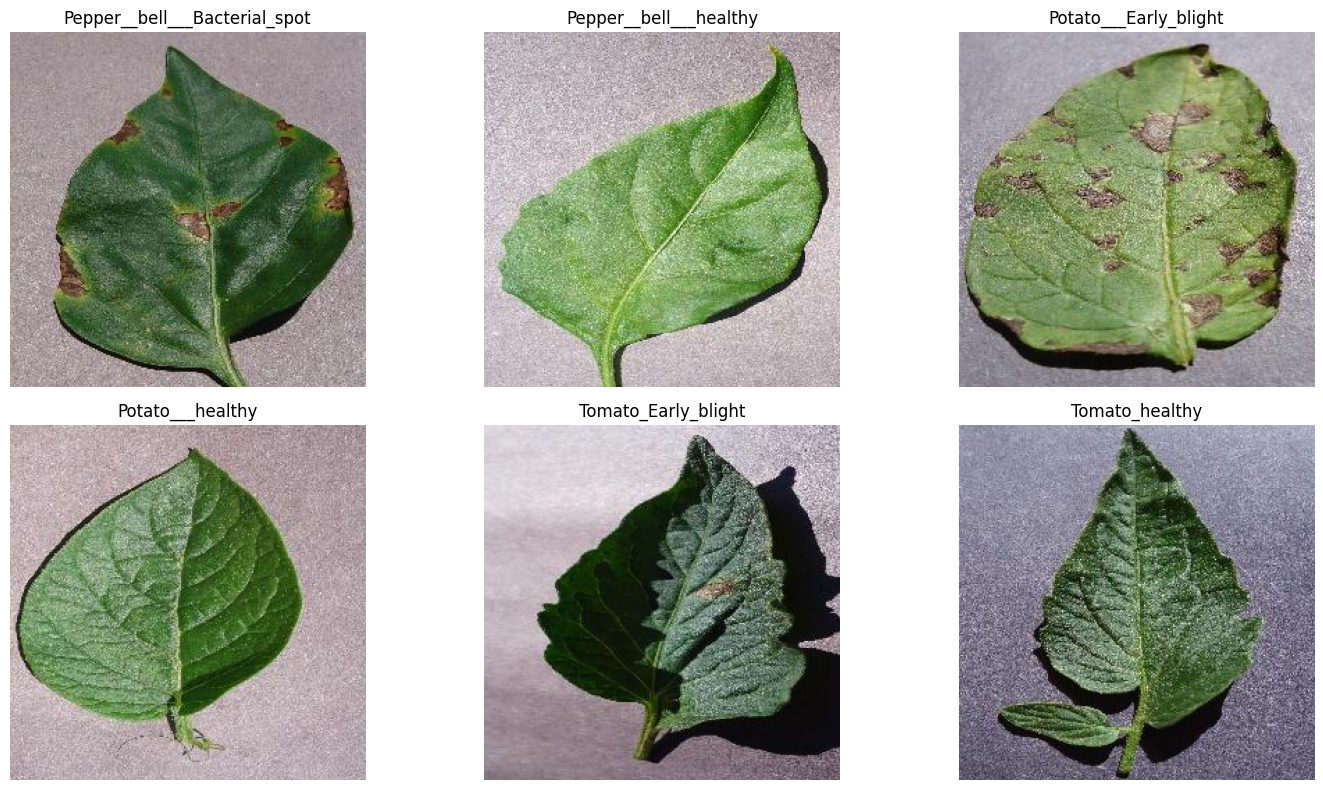

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)
    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import os
import random
import shutil

# Source dataset
source_dir = dataset_path

# Split folders
train_dir = r"C:\Users\dhuma\Desktop\Data Science\Deep Learning\Plant_Leaf_Disease_Detection\DataSet\train"
val_dir = r"C:\Users\dhuma\Desktop\Data Science\Deep Learning\Plant_Leaf_Disease_Detection\DataSet\validation"
test_dir = r"C:\Users\dhuma\Desktop\Data Science\Deep Learning\Plant_Leaf_Disease_Detection\DataSet\test"

# Create folders
for directory in [train_dir, val_dir, test_dir]:
    os.makedirs(directory, exist_ok=True)

# Fixed seed for reproducibility
random.seed(42)

# Split each class
for class_name in classes:
    
    class_source = os.path.join(source_dir, class_name)
    
    images = [
        f for f in os.listdir(class_source)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    
    random.shuffle(images)
    
    total = len(images)
    
    train_count = int(total * 0.70)
    val_count = int(total * 0.15)
    
    train_images = images[:train_count]
    val_images = images[train_count:train_count + val_count]
    test_images = images[train_count + val_count:]
    
    # Create class folders
    for split_dir in [train_dir, val_dir, test_dir]:
        os.makedirs(os.path.join(split_dir, class_name), exist_ok=True)
    
    # Copy images
    for image in train_images:
        shutil.copy2(
            os.path.join(class_source, image),
            os.path.join(train_dir, class_name, image)
        )
    
    for image in val_images:
        shutil.copy2(
            os.path.join(class_source, image),
            os.path.join(val_dir, class_name, image)
        )
    
    for image in test_images:
        shutil.copy2(
            os.path.join(class_source, image),
            os.path.join(test_dir, class_name, image)
        )

print("Dataset split completed successfully!")

Dataset split completed successfully!


In [5]:
for split_name, split_dir in [
    ("Training", train_dir),
    ("Validation", val_dir),
    ("Testing", test_dir)
]:
    
    print("\n", split_name)
    print("-" * 30)
    
    for class_name in classes:
        class_path = os.path.join(split_dir, class_name)
        count = len(os.listdir(class_path))
        print(class_name, ":", count)


 Training
------------------------------
Pepper__bell___Bacterial_spot : 697
Pepper__bell___healthy : 1034
Potato___Early_blight : 700
Potato___healthy : 106
Tomato_Early_blight : 700
Tomato_healthy : 1113

 Validation
------------------------------
Pepper__bell___Bacterial_spot : 149
Pepper__bell___healthy : 221
Potato___Early_blight : 150
Potato___healthy : 22
Tomato_Early_blight : 150
Tomato_healthy : 238

 Testing
------------------------------
Pepper__bell___Bacterial_spot : 151
Pepper__bell___healthy : 223
Potato___Early_blight : 150
Potato___healthy : 24
Tomato_Early_blight : 150
Tomato_healthy : 240


In [6]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 4350 files belonging to 6 classes.
Found 930 files belonging to 6 classes.
Found 938 files belonging to 6 classes.
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_healthy']
Number of classes: 6


### Data Augmentation + Normalization

In [7]:
from tensorflow.keras import layers

# Normalize pixel values from 0-255 to 0-1
normalization_layer = layers.Rescaling(1./255)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Normalization and Data Augmentation created successfully!")

Normalization and Data Augmentation created successfully!


In [8]:
from tensorflow.keras import models, layers

cnn_model = models.Sequential([
    
    # Input + Data Augmentation
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    normalization_layer,
    
    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten + Dense
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    
    # Dropout
    layers.Dropout(0.5),
    
    # Output Layer
    layers.Dense(len(class_names), activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [10]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "cnn_best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

print("Callbacks created successfully!")

Callbacks created successfully!


### CNN Model Training

In [11]:
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 273s 2s/step - accuracy: 0.5510 - loss: 1.2296 - val_accuracy: 0.7796 - val_loss: 0.6239
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.7630 - loss: 0.7029 - val_accuracy: 0.8602 - val_loss: 0.4507
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 330s 2s/step - accuracy: 0.8349 - loss: 0.5008 - val_accuracy: 0.9032 - val_loss: 0.3002
Epoch 4/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 277s 2s/step - accuracy: 0.8492 - loss: 0.4429 - val_accuracy: 0.9097 - val_loss: 0.2678
Epoch 5/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.8729 - loss: 0.3663 - val_accuracy: 0.9215 - val_loss: 0.2325
Epoch 6/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 293s 2s/step - accuracy: 0.8807 - loss: 0.3382 - val_accuracy: 0.8710 - val_loss: 0.3722
Epoch 7/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.8839 - loss: 0.3430 - val_accuracy: 0.9011 - val_loss: 0.2457
Epoch 8/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.9055 - loss: 0.2777 - val_accu

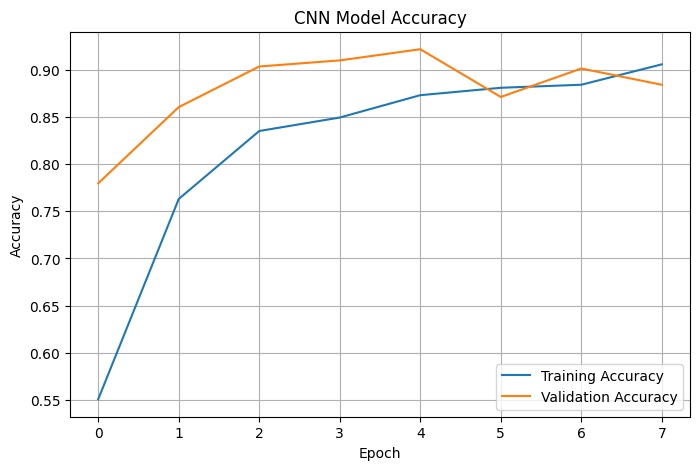

In [12]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

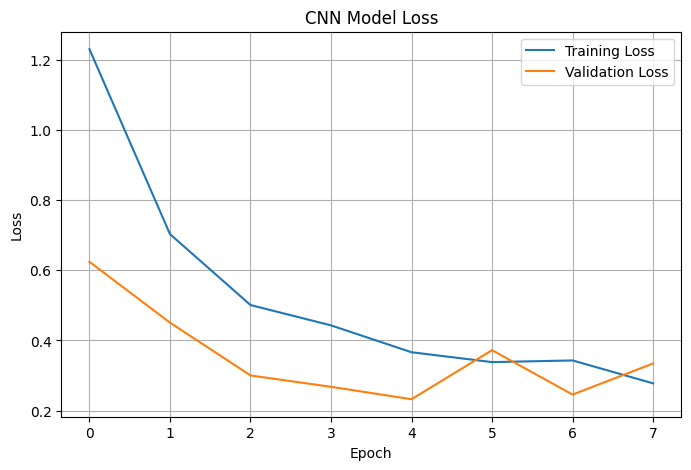

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [14]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 412ms/step - accuracy: 0.9094 - loss: 0.2256
Test Loss: 0.22556869685649872
Test Accuracy: 0.9093816876411438
Test Accuracy (%): 90.93816876411438


### Classification Report 

In [15]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Actual labels
y_true = np.concatenate([y.numpy() for x, y in test_ds])

# Predictions
y_pred_prob = cnn_model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification Report
print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 426ms/step
Classification Report:

                               precision    recall  f1-score   support

Pepper__bell___Bacterial_spot       0.89      0.79      0.84       151
       Pepper__bell___healthy       0.84      0.98      0.90       223
        Potato___Early_blight       0.96      0.97      0.96       150
             Potato___healthy       0.00      0.00      0.00        24
          Tomato_Early_blight       0.92      0.87      0.89       150
               Tomato_healthy       0.96      1.00      0.98       240

                     accuracy                           0.91       938
                    macro avg       0.76      0.77      0.76       938
                 weighted avg       0.89      0.91      0.90       938



C:\Users\dhuma\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dhuma\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dhuma\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [16]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.concatenate([y.numpy() for x, y in train_ds])
)

class_weights = dict(enumerate(class_weights_values))

print("Class Weights:")
for i, weight in class_weights.items():
    print(class_names[i], ":", round(weight, 2))

Class Weights:
Pepper__bell___Bacterial_spot : 1.04
Pepper__bell___healthy : 0.7
Potato___Early_blight : 1.04
Potato___healthy : 6.84
Tomato_Early_blight : 1.04
Tomato_healthy : 0.65


In [17]:
history_weighted = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 270s 2s/step - accuracy: 0.7418 - loss: 0.7735 - val_accuracy: 0.8892 - val_loss: 0.2911
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 467s 3s/step - accuracy: 0.7977 - loss: 0.5452 - val_accuracy: 0.8914 - val_loss: 0.2836
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.8308 - loss: 0.4896 - val_accuracy: 0.8742 - val_loss: 0.2923


In [18]:
weighted_test_loss, weighted_test_accuracy = cnn_model.evaluate(test_ds)

print("Weighted CNN Test Loss:", weighted_test_loss)
print("Weighted CNN Test Accuracy:", weighted_test_accuracy)
print("Weighted CNN Test Accuracy (%):", weighted_test_accuracy * 100)

30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 414ms/step - accuracy: 0.9126 - loss: 0.2655
Weighted CNN Test Loss: 0.26546958088874817
Weighted CNN Test Accuracy: 0.9125799536705017
Weighted CNN Test Accuracy (%): 91.25799536705017


In [19]:
from sklearn.metrics import classification_report
import numpy as np

y_true_weighted = np.concatenate([y.numpy() for x, y in test_ds])

y_pred_prob_weighted = cnn_model.predict(test_ds)
y_pred_weighted = np.argmax(y_pred_prob_weighted, axis=1)

print("Weighted CNN Classification Report:\n")

print(classification_report(
    y_true_weighted,
    y_pred_weighted,
    target_names=class_names
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 379ms/step
Weighted CNN Classification Report:

                               precision    recall  f1-score   support

Pepper__bell___Bacterial_spot       0.90      0.86      0.88       151
       Pepper__bell___healthy       0.92      0.84      0.88       223
        Potato___Early_blight       0.95      0.95      0.95       150
             Potato___healthy       0.47      0.92      0.62        24
          Tomato_Early_blight       0.93      0.89      0.91       150
               Tomato_healthy       0.97      1.00      0.98       240

                     accuracy                           0.91       938
                    macro avg       0.86      0.91      0.87       938
                 weighted avg       0.92      0.91      0.92       938



### Confusion matrix

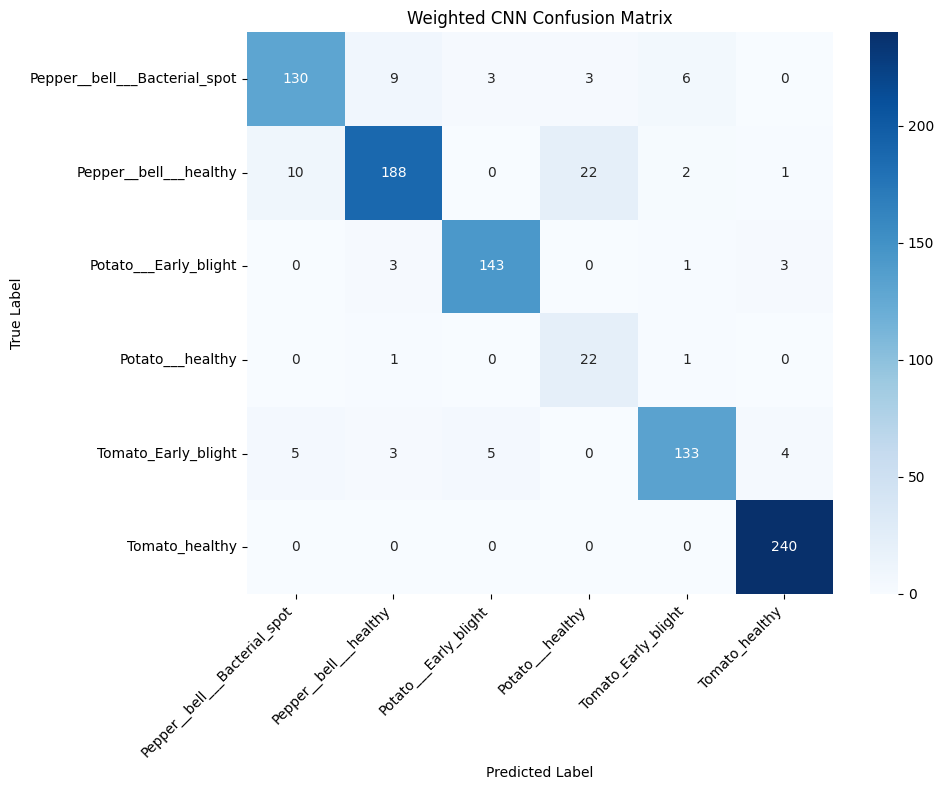

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_weighted, y_pred_weighted)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Weighted CNN Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

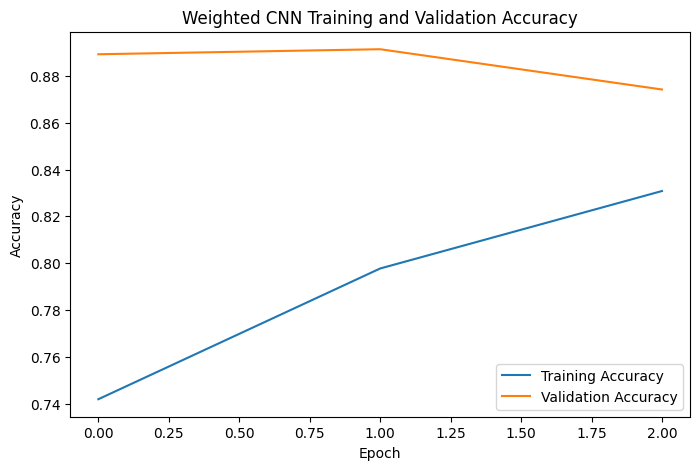

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history_weighted.history["accuracy"], label="Training Accuracy")
plt.plot(history_weighted.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Weighted CNN Training and Validation Accuracy")
plt.legend()
plt.show()

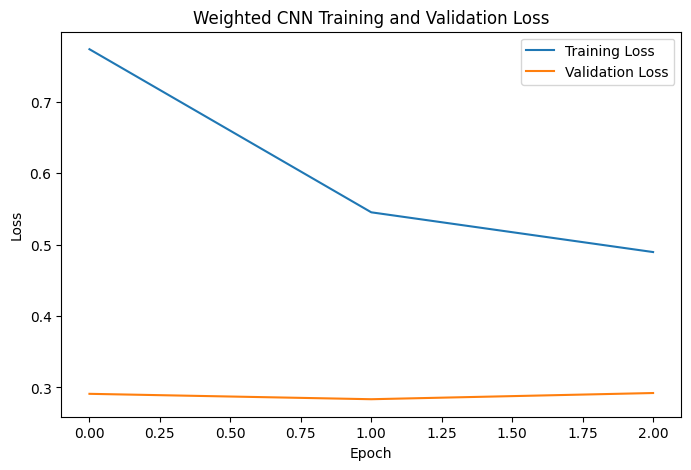

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history_weighted.history["loss"], label="Training Loss")
plt.plot(history_weighted.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Weighted CNN Training and Validation Loss")
plt.legend()
plt.show()

In [23]:
cnn_model.save("plant_disease_weighted_cnn.keras")

print("Weighted CNN model saved successfully!")

Weighted CNN model saved successfully!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step


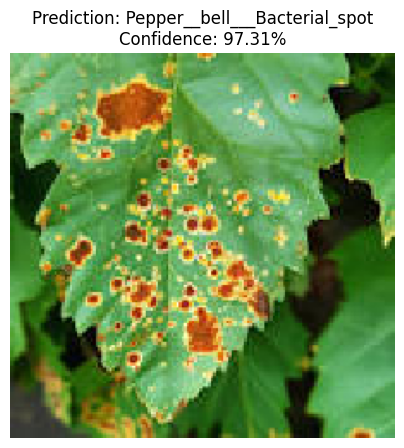

Predicted Class: Pepper__bell___Bacterial_spot
Confidence: 97.31%


In [24]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

image_path = r"C:\Users\dhuma\Downloads\Leaf image.jpg"

# Load image
img = load_img(image_path, target_size=(224, 224))

# Convert image to array
img_array = img_to_array(img)

# Normalize
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Prediction
prediction = cnn_model.predict(img_array)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

print("Predicted Class:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")

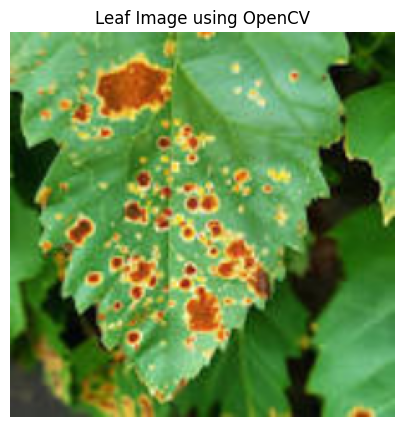

Original Image Shape: (148, 148, 3)
Resized Image Shape: (224, 224, 3)


In [25]:
import cv2
import matplotlib.pyplot as plt

image_path = r"C:\Users\dhuma\Downloads\Leaf image.jpg"

# Read image using OpenCV
image = cv2.imread(image_path)

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Resize image
resized_image = cv2.resize(image_rgb, (224, 224))

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(resized_image)
plt.axis("off")
plt.title("Leaf Image using OpenCV")
plt.show()

print("Original Image Shape:", image.shape)
print("Resized Image Shape:", resized_image.shape)

In [26]:
import os

print("Notebook folder path:", os.getcwd())

Notebook folder path: C:\Users\dhuma\Desktop\Data Science\Deep Learning\Plant_Leaf_Disease_Detection\Notebook
